# Spectra at random locations, along with initial high-resolution image

# BEPS at Random Location

In [ ]:
#handy helper function
def det_phase_offset(phase_mat_lin):
    """Input:
        - phase mat: numpy vector of size N, containing the phase values of every point
    Output:
        - phase_offset: float of the phase offset requried to center the phase
        Here centering means that one side will be 0 and the other will be pi,
        so the loop can be projected as A*cos(phi)"""

    #First calculate the histogram of the phase values

    num_bins = 150 #number of bins in histogram
    hist, bin_edges = np.histogram(phase_mat_lin, bins = num_bins)

    #Remove zero values. Sometimes, when phase is undefined the zero bin will have a peak. Remove this,
    #and replace it with the average of the two surrounding bins on either side
    hist[num_bins//2-5:num_bins//2+5] = 0.5*(hist[num_bins//2-5] + hist[num_bins//2+5])

    #Now find the two peaks by finding the two relative maxima

    peak_positions = find_peaks(hist, distance = num_bins//3)

    phase_1 = bin_edges[peak_positions[0][0]]
    phase_2 = bin_edges[peak_positions[0][1]]

    print ('The phase difference is {}'.format(np.round(np.abs(phase_1 - phase_2),3)))
    print ('The phase offset is {}'.format(np.round(phase_1,3)))

    #plt.plot(phase_1, hist[peak_positions[0][0]], 'rx')
    #plt.plot(phase_2, hist[peak_positions[0][1]], 'rx')

    if np.abs(np.abs(phase_1 - phase_2) - np.pi) >0.5:
        print('There was a problem with automatic phase offset determination! Do it manually before proceeding!!')
    phase_offset = phase_1

    return phase_offset

def usid_to_pr(h5_f, sho_fit_group = None):

    """This function takes as an input a h5 path to a USID file for a BEPS measurement,
    and then returns a piezoresponse matrix along with the voltage vector for the first cycle
    Inputs:
    h5_path: string - path to the usid file containing the BEPS measurement

    Output:
    pr_array: numpy ndarray - numpy array containing the piezoresponse matrix in 3D form
    vdc_vec: numpy ndarray - numpy array containing the voltage vector

    """
    #h5_f = h5py.File(h5_path, 'r')
    if sho_fit_group is None:
        sho_mat = h5_f['Measurement_000/Channel_000/Raw_Data-SHO_Fit_000/Guess']
        spec_val = h5_f['Measurement_000/Channel_000/Raw_Data-SHO_Fit_000/Spectroscopic_Values']
        pos_inds = h5_f['Measurement_000/Channel_000/Position_Indices']
        points_measured = sho_mat['Quality Factor'][:,1]!=0
        points_measured = np.where(points_measured==True)[0]

        #steps_per_cycle = h5_f['Measurement_000'].attrs['VS_steps_per_full_cycle'] * h5_f['Measurement_000'].attrs['VS_number_of_cycles']
    else:
        sho_mat = sho_fit_group['Fit']
        spec_val = sho_fit_group['Spectroscopic_Values']
        pos_inds = sho_fit_group.parent['Position_Indices']
        points_measured = sho_mat['Quality Factor'][:,1]!=200
        points_measured = np.where(points_measured==True)[0]

    #steps_per_cycle = h5_f['Measurement_000'].attrs['VS_steps_per_full_cycle'] * h5_f['Measurement_000'].attrs['VS_number_of_cycles']

    pos_dim_sizes = [np.max(pos_inds[:,0])+1, np.max(pos_inds[:,1]+1)]


    #Extract the amplitude and phase from the guess or fit
    sho_mat_ndim = sho_mat[:].reshape(pos_dim_sizes[0], pos_dim_sizes[1], -1)
    amp_mat_ndim = sho_mat_ndim['Amplitude [V]']

    # points_measured = sho_mat['Quality Factor'][:,1]!=0
    # points_measured = np.where(points_measured==True)[0]

    phase_mat_ndim = sho_mat_ndim['Phase [rad]']
    phase_mat = sho_mat['Phase [rad]']

    #First calculate phase offset

    #Be careful for this: we need to exclude points that have not been measured!
    phase_mat_ndim_measured = phase_mat.copy()[points_measured,:]
    phase_offset = 0#1.75#det_phase_offset(phase_mat_ndim_measured.ravel())

#     pr_mat_ndim_real = (amp_mat_ndim*np.cos(phase_mat_ndim-phase_offset))[:,:,steps_per_cycle:]
#     pr_mat_ndim_imag = (amp_mat_ndim*np.sin(phase_mat_ndim-phase_offset))[:,:,steps_per_cycle:]
    pr_mat_ndim_real_all = (amp_mat_ndim*np.cos(phase_mat_ndim-phase_offset))
    pr_mat_ndim_imag_all = (amp_mat_ndim*np.sin(phase_mat_ndim-phase_offset))

    pr_mat_ndim_real = np.zeros((256,256,64*5))
    pr_mat_ndim_imag = np.zeros((256,256,64*5))
    for k in range (64*5):
        pr_mat_ndim_real[:,:,k] = pr_mat_ndim_real_all[:,:,k*2+1]
        pr_mat_ndim_imag[:,:,k] = pr_mat_ndim_imag_all[:,:,k*2+1]

    vdc = spec_val[0,:]
    vdc_vec = np.zeros(int(len(vdc)/2))
    for i in range (int(len(vdc)/2)):
        vdc_vec [i] = vdc[i*2]

    h5_f.close()

    return [pr_mat_ndim_real, pr_mat_ndim_imag], vdc_vec, points_measured


Download data

In [ ]:
!wget -O PZT_2um_0031.h5 "https://www.dropbox.com/scl/fi/voghgcde2ejaxvmo47ueq/PZT_2um_0031.h5?rlkey=qaj8za7ad3togy5i5zbthcygs&st=xr46kz3h&dl=0"
!wget -O PZT_Ramdon_BEPS_2um_0032.h5 "https://www.dropbox.com/scl/fi/192lnqgss86eonlo23uif/PZT_Ramdon_BEPS_2um_0032.h5?rlkey=dtxkbuuw7y9xrvywvzt62nhge&st=mkve6net&dl=0"

--2026-08-20 14:37:59--  https://www.dropbox.com/scl/fi/voghgcde2ejaxvmo47ueq/PZT_2um_0031.h5?rlkey=qaj8za7ad3togy5i5zbthcygs&st=xr46kz3h&dl=0
Resolving www.dropbox.com (www.dropbox.com)... 162.125.2.18, 2620:100:601c:18::a27d:612
Connecting to www.dropbox.com (www.dropbox.com)|162.125.2.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://ucb9d04a6c5f08f99f68ce5a8dd9.dl.dropboxusercontent.com/cd/0/inline/DGg1Ol0FtLZf6MCXREf5HlTtTHy1TpXhcVYro2Ru4atbvL7axeSJzx4twwCP9le_yc9HkMDtMCsGGpYDZqoQ4uh-PeVkf3Csf6_7l2X2mOOBr9Ebq00zQlD5yHFnN2vcc0oPIHBo0zEwdcji4XCpL8Tz/file# [following]
--2026-08-20 14:37:59--  https://ucb9d04a6c5f08f99f68ce5a8dd9.dl.dropboxusercontent.com/cd/0/inline/DGg1Ol0FtLZf6MCXREf5HlTtTHy1TpXhcVYro2Ru4atbvL7axeSJzx4twwCP9le_yc9HkMDtMCsGGpYDZqoQ4uh-PeVkf3Csf6_7l2X2mOOBr9Ebq00zQlD5yHFnN2vcc0oPIHBo0zEwdcji4XCpL8Tz/file
Resolving ucb9d04a6c5f08f99f68ce5a8dd9.dl.dropboxusercontent.com (ucb9d04a6c5f08f99f68ce5a8dd9.dl.dropboxusercontent.com)... 

Load image data

In [ ]:
BEPFM = h5py.File(r'PZT_2um_0031.h5', 'r+')

In [ ]:
rz = 256  #set the size of dataset

amp = BEPFM['Measurement_000/Channel_000/Raw_Data-SHO_Fit_001/Guess']['Amplitude [V]'].reshape(rz,rz)
pha = BEPFM['Measurement_000/Channel_000/Raw_Data-SHO_Fit_001/Guess']['Phase [rad]'].reshape(rz,rz)
fre = BEPFM['Measurement_000/Channel_000/Raw_Data-SHO_Fit_001/Guess']['Frequency [Hz]'].reshape(rz,rz)
q = BEPFM['Measurement_000/Channel_000/Raw_Data-SHO_Fit_001/Guess']['Quality Factor'].reshape(rz,rz)
r2 = BEPFM['Measurement_000/Channel_000/Raw_Data-SHO_Fit_001/Guess']['R2 Criterion'].reshape(rz,rz)
topo = BEPFM['Measurement_000/Channel_001/Raw_Data']['r'].reshape(rz,rz)
pola = amp*np.cos(pha)

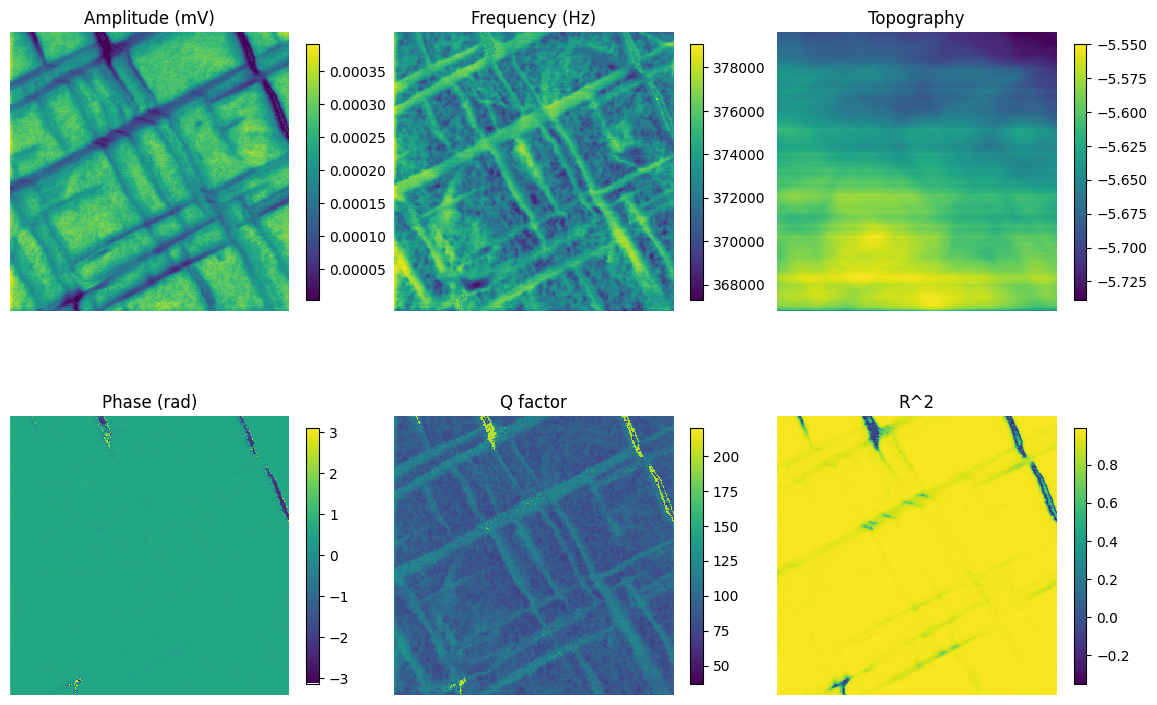

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(12, 8))
fig.subplots_adjust(left=0.02, bottom=0.06, right=0.95, top=0.94, wspace=0.1)
# Make 4 subplots:
cm = 'viridis'
shrink = 0.8

im1 = axs[0, 0].imshow(amp, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im1, ax=axs[0, 0], shrink = shrink)
#axs[0, 0].set_title("Amplitude (µV)")
axs[0, 0].set_title("Amplitude (mV)")
axs[0, 0].axis('off')

im2 = axs[1, 0].imshow(pha, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im2, ax=axs[1, 0], shrink = shrink)
axs[1, 0].set_title("Phase (rad)")
axs[1, 0].axis('off')

im3 = axs[0, 1].imshow(fre, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im3, ax=axs[0, 1], shrink = shrink)
axs[0, 1].set_title("Frequency (Hz)")
axs[0, 1].axis('off')

im4 = axs[1, 1].imshow(q, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im4, ax=axs[1, 1], shrink = shrink)
axs[1, 1].set_title("Q factor")
axs[1, 1].axis('off')

im5 = axs[0, 2].imshow(topo, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im5, ax=axs[0, 2], shrink = shrink)
axs[0, 2].set_title("Topography")
axs[0, 2].axis('off')

im6 = axs[1, 2].imshow(r2, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im6, ax=axs[1, 2], shrink = shrink)
axs[1, 2].set_title("R^2")
axs[1, 2].axis('off')
plt.show()

Load spectra data

In [ ]:
BEPS = h5py.File(r'PZT_Ramdon_BEPS_2um_0032.h5', 'r+')

The phase difference is 3.0160000324249268
The phase offset is -2.4709999561309814


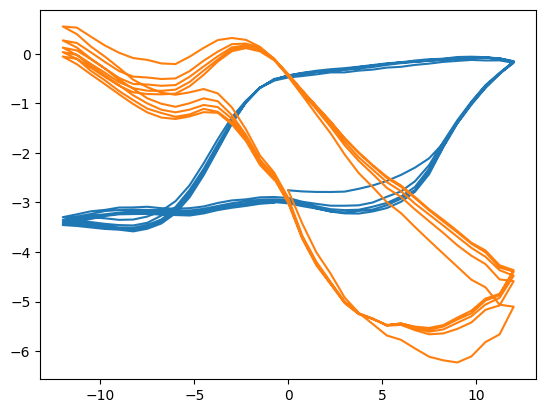

In [ ]:
sho_mat=BEPS['Measurement_000/Channel_000/Raw_Data-SHO_Fit_001/Fit']
spec_val = BEPS['Measurement_000/Channel_000/Raw_Data-SHO_Fit_000/Spectroscopic_Values']
pos_inds = BEPS['Measurement_000/Channel_000/Position_Indices']
pos_dim_sizes = [np.max(pos_inds[:,0])+1, np.max(pos_inds[:,1]+1)]

sho_mat_ndim = sho_mat[:].reshape(pos_dim_sizes[0], pos_dim_sizes[1], -1)
amp_mat_ndim = sho_mat_ndim['Amplitude [V]']
phase_mat_ndim = sho_mat_ndim['Phase [rad]']

pr_mat_ndim = (amp_mat_ndim*np.cos(phase_mat_ndim+det_phase_offset(phase_mat_ndim)))*1E5

p_onfield = np.zeros((256,256,64*5))
p_offfield = np.zeros((256,256,64*5))
v_step = np.zeros(64*5)
#pr1 = pr_mat_ndim1.mean(axis = (0,1))

for i in range (64*5):
  p_onfield[:,:,i] = pr_mat_ndim[:,:,2*i]
  p_offfield[:,:,i] = pr_mat_ndim[:,:,2*i+1]
  v_step[i] = spec_val[0,2*i]

#extract spectra from measured points
_, _, points_measured = usid_to_pr(BEPS)

all_offfield= p_offfield.reshape((256*256, 64*5))
measured_offfield = all_offfield[points_measured,]

all_onfield= p_onfield.reshape((256*256, 64*5))
measured_onfield = all_onfield[points_measured,]

plt.plot(v_step, measured_offfield.mean(0))
plt.plot(v_step, measured_onfield.mean(0))

In [ ]:
smoothed_beps = np.zeros(measured_offfield.shape)
for i in range (len(measured_offfield)):
  y = measured_offfield[i,]
  step = v_step
  yhat = savgol_filter(y, 7, 1)
  smoothed_beps[i, ] = yhat
smoothed_beps.shape

(4001, 320)

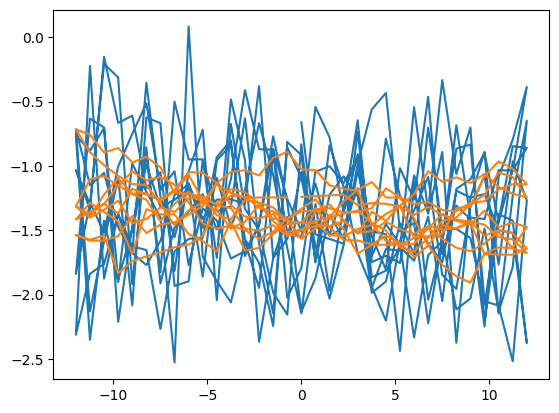

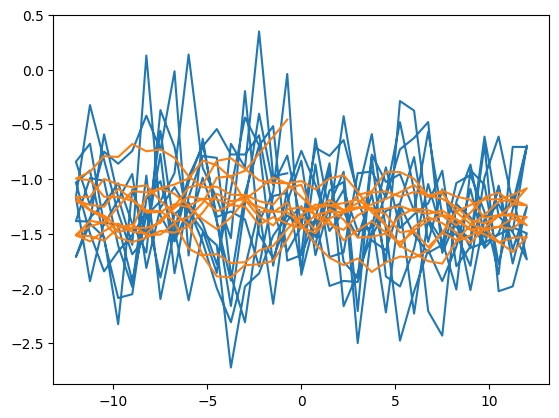

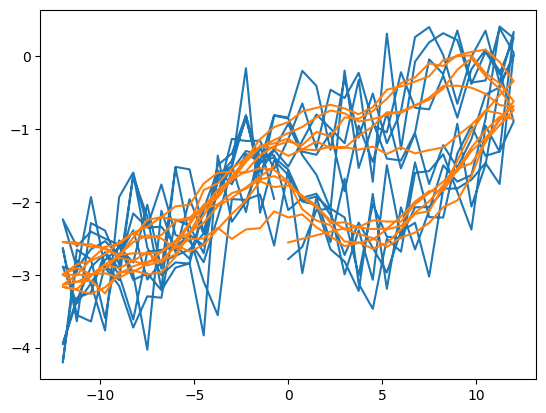

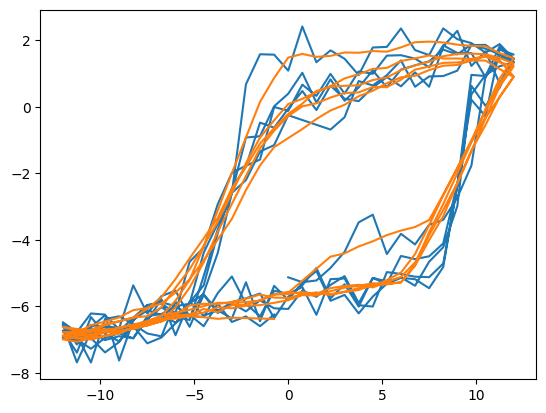

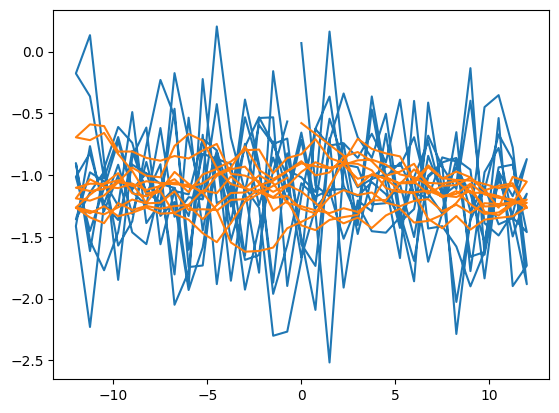

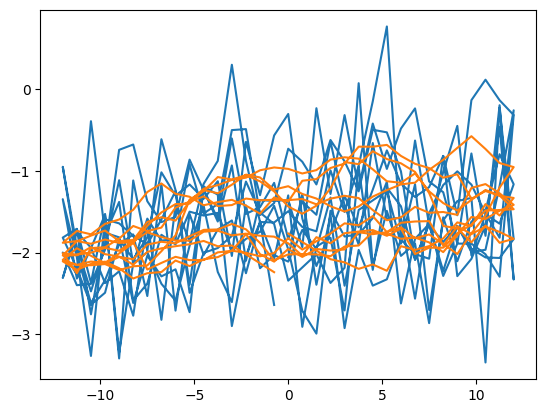

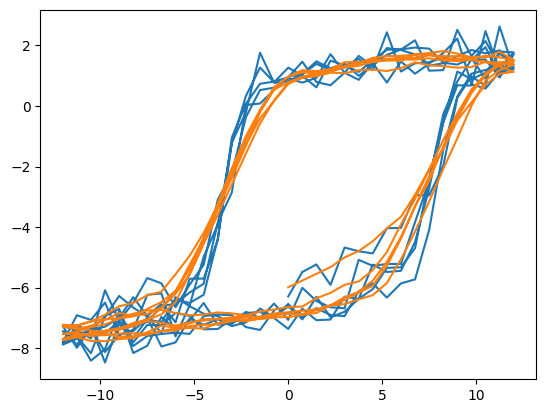

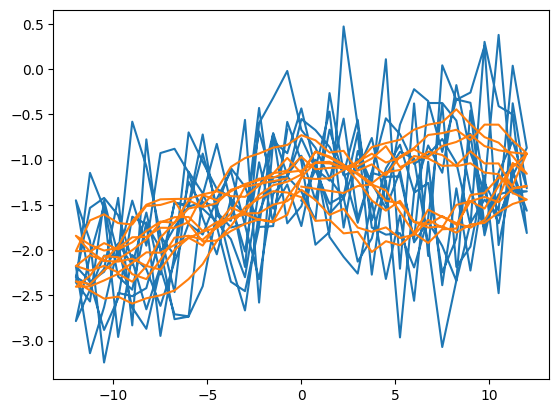

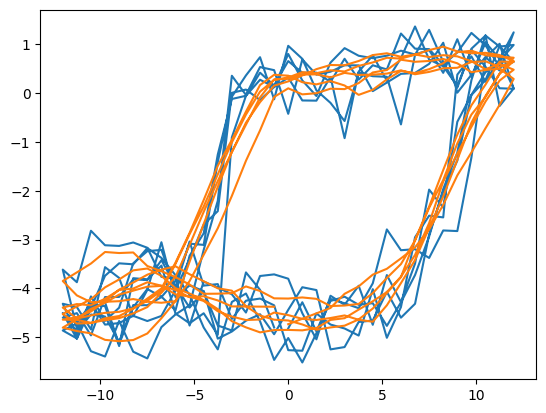

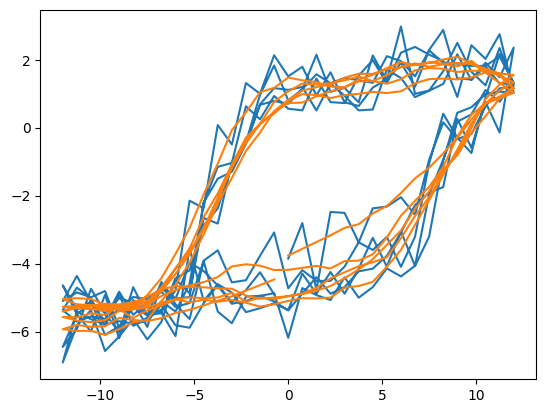

In [ ]:
for i in range (10):
  plt.plot(v_step, measured_offfield[i*100,])
  plt.plot(v_step, smoothed_beps[i*100,])
  plt.show()

Text(0, 0.5, 'Piezoresponse (a.u.)')

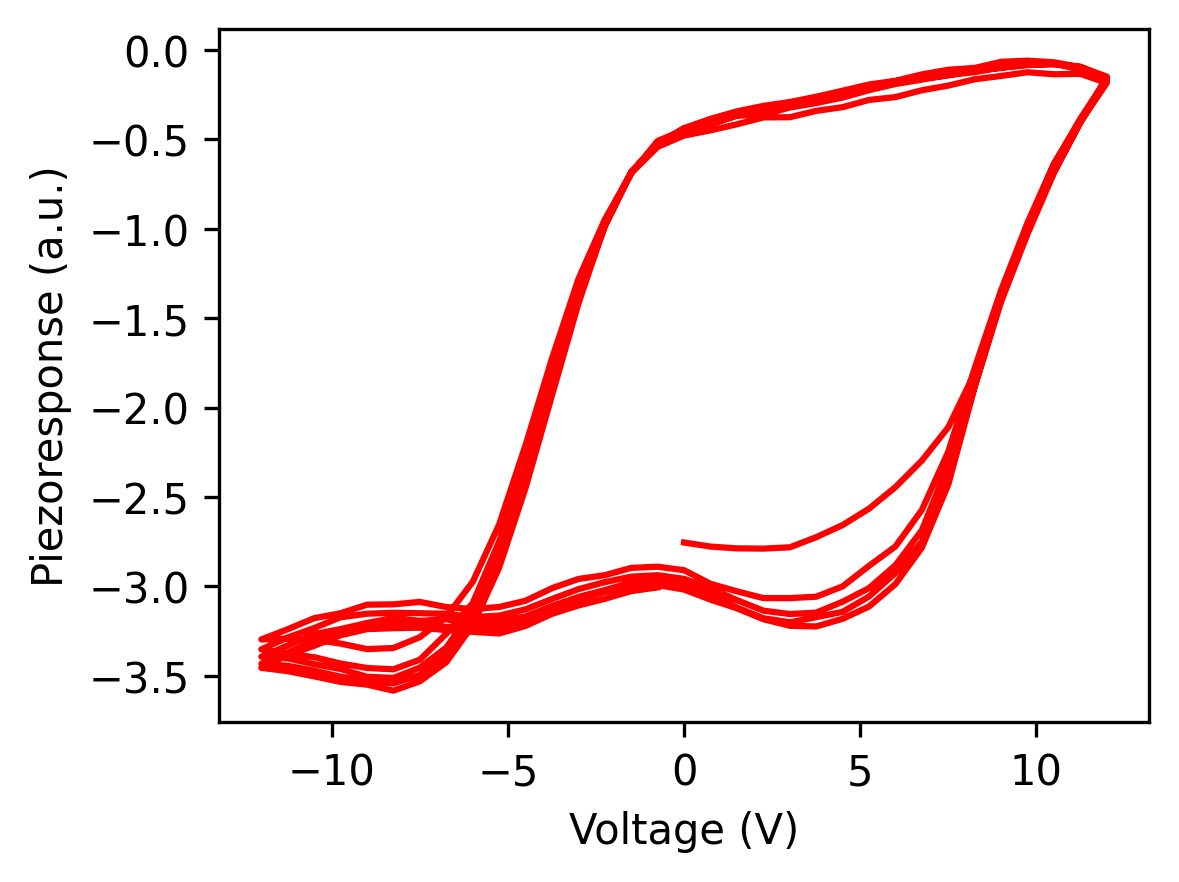

In [ ]:
plt.figure(figsize = (4, 3), dpi = 300)
plt.plot(v_step, measured_offfield.mean(0), c = 'r')
plt.xlabel("Voltage (V)")
plt.ylabel("Piezoresponse (a.u.)")

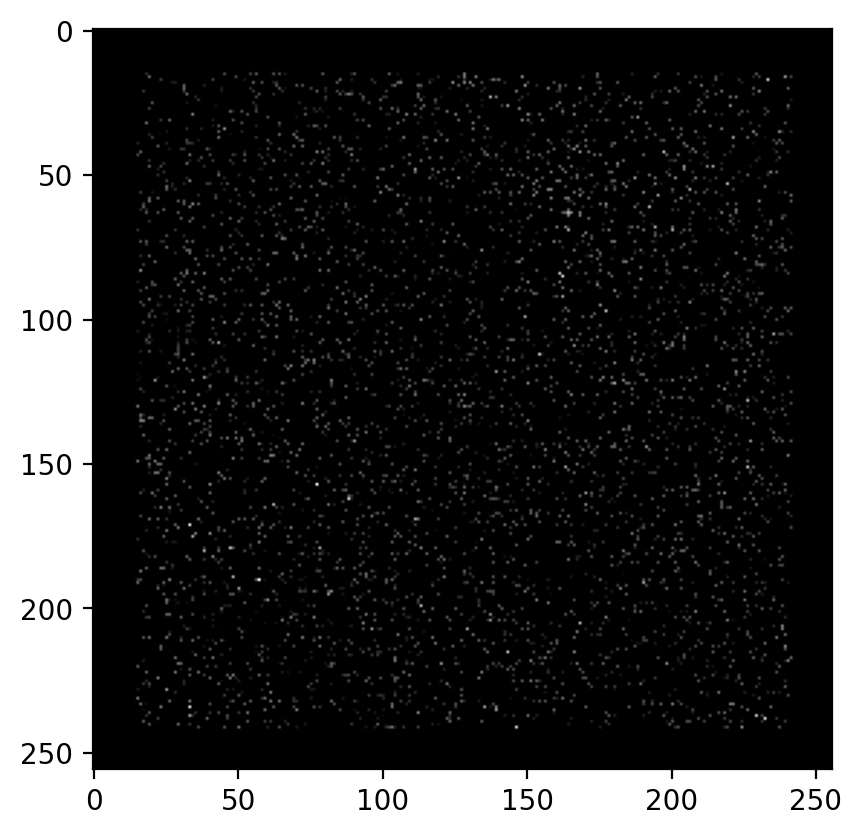

In [ ]:
plt.figure(dpi = 200)
plt.imshow(all_offfield.mean(1).reshape((256, 256)), cmap = 'Greys')

Prepare image and spectra data for train---need to link corresponding image patches and spectra

(4001, 30, 30)

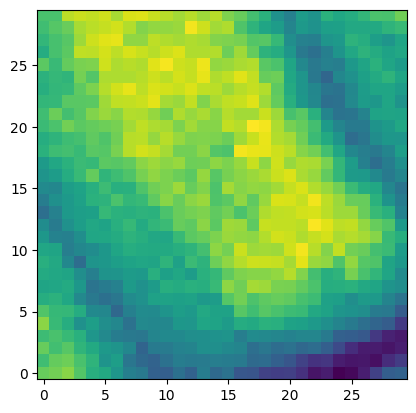

In [ ]:
image = amp
coordinates = get_grid_coords(image, 1)
coor = coordinates[points_measured]

windowsize = 30
img, com, _ = get_subimages(image, coor, windowsize)

indices = np.asarray(com, dtype= int)

img = img[:,:,:,0]
plt.imshow(img[1500,], origin = 'lower')

img.shape

# Save Random BEPS as npz

In [ ]:
np.savez('random_BEPS_PZT.npz', fullimg = image, imgpatches = img[:,1:-1,1:-1], spectra = smoothed_beps,
         v_step = v_step, coordinates = coor)